# Member 3 — Assigned Project Notebook

**Division:** Sections 1–12 (shared by everyone) + Sections 15.7–15.12: N-best results and misclassification/error analysis. This part uses prediction arrays and evaluation results produced in Sections 14–15.6 when the group combines the work.

**Important:** Sections 1–12 are intentionally included because they are the common dataset exploration, preprocessing, and DataLoader foundation required for every member. The assigned later sections are copied from the master notebook without changing the project logic.


# 1. Tree Species Classification

This project develops image classification models for identifying tree species.

The project uses transfer learning with two ResNet architectures:

- ResNet18
- ResNet50

The models will be trained, validated, tested, and evaluated using accuracy, precision, recall, F1-score, confusion matrices, and n-best classification results.

# 2. Import Libraries

In [64]:
import torch.nn as nn
import torch.optim as optim


import matplotlib.pyplot as plt

print("All libraries imported successfully")
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
import os
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

print("All libraries imported successfully")

All libraries imported successfully
All libraries imported successfully


# 3. Define Dataset Paths

### Dataset Path

The tree dataset is stored separately from the notebook. Update `data_dir`
below to the local location of the downloaded dataset before running the notebook.

In [65]:
# Update this path to the location of the downloaded tree dataset
data_dir = r"D:\machineLearning\Neutral\tree"

train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "val")
test_dir = os.path.join(data_dir, "test")

print("Train folder:", train_dir)
print("Validation folder:", val_dir)
print("Test folder:", test_dir)

Train folder: D:\machineLearning\Neutral\tree\train
Validation folder: D:\machineLearning\Neutral\tree\val
Test folder: D:\machineLearning\Neutral\tree\test


# 4. Check Dataset Folders

Before loading the images, we check that the training, validation, and test folders exist at the expected locations.

The dataset is divided into three parts:

- **Training set:** used to train the machine learning model.
- **Validation set:** used to monitor the model during development and training.
- **Test set:** used for the final evaluation of the trained model.

This check helps us make sure that the dataset paths are correct before we start loading the images.

In [66]:
print("Train folder exists:", os.path.exists(train_dir))
print("Validation folder exists:", os.path.exists(val_dir))
print("Test folder exists:", os.path.exists(test_dir))

Train folder exists: True
Validation folder exists: True
Test folder exists: True


# 5. Load the Dataset

The dataset is organized into folders where each folder represents one tree species.

For example, the training folder contains separate folders for different species:

```text
train/
├── Acer palmatum/
├── Cedrus deodara/
├── Celtis sinensis/
├── Ginkgo biloba/
└── ...

In [67]:

train_data = datasets.ImageFolder(train_dir)
val_data = datasets.ImageFolder(val_dir)
test_data = datasets.ImageFolder(test_dir)

print("Dataset loaded successfully!")

Dataset loaded successfully!


# 6. Explore the Tree Species Classes

Each tree species is treated as a separate classification class.

We will now display the class names detected by PyTorch and count how many different species are included in the dataset.

This information is important because the final classification layer of our ResNet models needs one output for each tree species.

In [68]:
print("Tree species/classes:")

for i, class_name in enumerate(train_data.classes):
    print(i, ":", class_name)

print("\nNumber of classes:", len(train_data.classes))

Tree species/classes:
0 : Acer palmatum
1 : Cedrus deodara
2 : Celtis sinensis
3 : Cinnamomum camphora (Linn) Presl
4 : Elaeocarpus decipiens
5 : Flowering cherry
6 : Ginkgo biloba
7 : Koelreuteria paniculata
8 : Lagerstroemia indica
9 : Liquidambar formosana
10 : Liriodendron chinense
11 : Magnolia grandiflora L
12 : Magnolia liliflora Desr
13 : Michelia chapensis
14 : Osmanthus fragrans
15 : Photinia serratifolia
16 : Platanus
17 : Prunus cerasifera f. atropurpurea
18 : Salix babylonica
19 : Sapindus saponaria
20 : Styphnolobium japonicum
21 : Triadica sebifera
22 : Zelkova serrata

Number of classes: 23


# 7. Number of Images

Next, we check the number of images in each part of the dataset.

The training set is used to train the models, the validation set is used during model development, and the test set is kept for the final evaluation.

Knowing the number of images gives us an overview of the size of the dataset before training the models.

In [69]:
print("Number of training images:", len(train_data))
print("Number of validation images:", len(val_data))
print("Number of test images:", len(test_data))

print("\nTotal images:", len(train_data) + len(val_data) + len(test_data))

Number of training images: 3850
Number of validation images: 482
Number of test images: 472

Total images: 4804


# 8. Inspect Example Images

Before applying preprocessing techniques, we inspect several images from the training dataset.

This helps us understand the visual characteristics of the dataset and identify possible issues that could affect classification performance.

We will look for differences such as:

- Image size and aspect ratio
- Lighting conditions
- Backgrounds
- Camera viewpoint
- Tree position in the image
- Image quality
- Visual differences between tree species

These observations will help us decide which preprocessing and data augmentation techniques should be used later.

# 9. Display One Training Image

We first display one image from the training dataset together with its tree species label.

Image size: (1200, 1600)
Label number: 0
Tree species: Acer palmatum


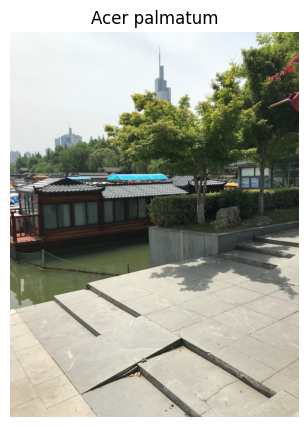

In [70]:
image, label = train_data[0] #gets the first image from the training dataset.

print("Image size:", image.size)
print("Label number:", label)
print("Tree species:", train_data.classes[label])

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(train_data.classes[label])
plt.axis("off")
plt.show()

# 10. Inspect the Training Images

## 10.1 Display Several Training Images

Looking at several images gives us a better understanding of the variation within the dataset.

The images may differ in viewpoint, lighting, background, and the position of the tree. These variations are important because the model needs to learn features that are related to the tree species rather than memorizing a particular image background or composition.

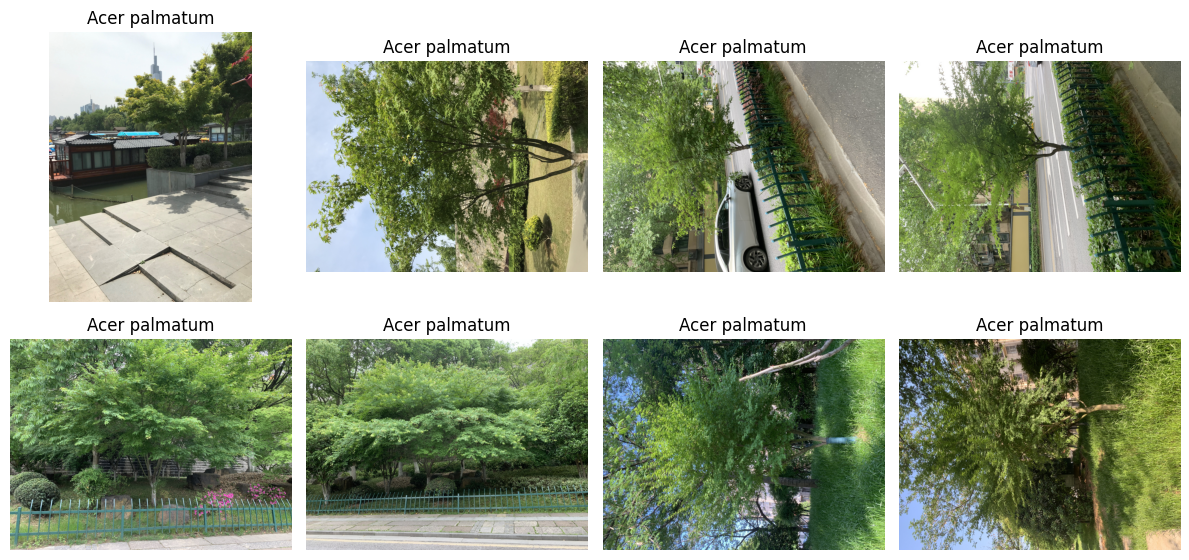

In [71]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]

    ax.imshow(image)
    ax.set_title(train_data.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.2 Check Image Sizes

Images in a dataset may have different resolutions.

We check several images to see whether the dataset contains images with different dimensions.

This is important because the images will later need to be converted into a consistent size before they are given to the neural network.

In [72]:
for i in range(10):
    image, label = train_data[i]
    print(i, train_data.classes[label], image.size)

0 Acer palmatum (1200, 1600)
1 Acer palmatum (1600, 1200)
2 Acer palmatum (1600, 1200)
3 Acer palmatum (1600, 1200)
4 Acer palmatum (1600, 1200)
5 Acer palmatum (1600, 1200)


6 Acer palmatum (1600, 1200)
7 Acer palmatum (1600, 1200)
8 Acer palmatum (1600, 1200)
9 Acer palmatum (1600, 1200)


## 10.3 Inspect Images from Different Tree Species

The previous examples mainly came from the first class because the images in the dataset are organized by class.

To better understand the dataset, we now display one example image from each of several different tree species.

This allows us to compare the visual characteristics of different classes and identify possible differences in image orientation, background, lighting, and image composition.

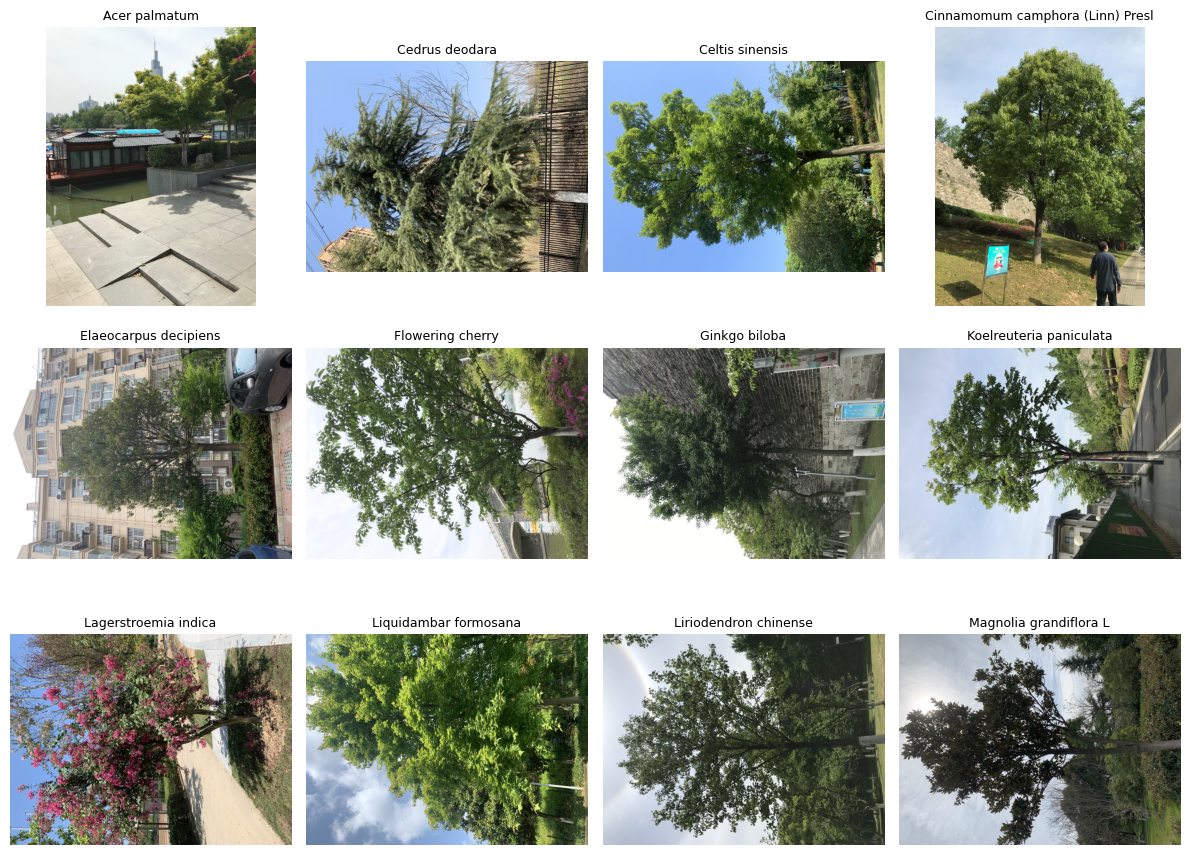

In [73]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

# Select one image from 12 different classes
for i, ax in enumerate(axes.flat):
    class_name = train_data.classes[i]
    
    # Find the first image belonging to this class
    for image_index in range(len(train_data)):
        _, label = train_data[image_index]
        
        if label == i:
            image, _ = train_data[image_index]
            break
    
    ax.imshow(image)
    ax.set_title(class_name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.4 Investigate Image Orientation

The initial inspection showed that the dataset contains both portrait and landscape images.

Some images also appear to have different orientations. We therefore inspect the dimensions of images from different classes before deciding whether additional preprocessing is necessary.

The goal is to determine whether the variation is simply due to different aspect ratios or whether some images require orientation correction.

In [74]:
for class_index in range(10):
    class_name = train_data.classes[class_index]
    
    for image_index in range(len(train_data)):
        image, label = train_data[image_index]
        
        if label == class_index:
            print(class_name, "->", image.size)
            break

Acer palmatum -> (1200, 1600)
Cedrus deodara -> (1600, 1200)
Celtis sinensis -> (1600, 1200)
Cinnamomum camphora (Linn) Presl -> (1200, 1600)
Elaeocarpus decipiens -> (1600, 1200)
Flowering cherry -> (1600, 1200)
Ginkgo biloba -> (1600, 1200)
Koelreuteria paniculata -> (1600, 1200)
Lagerstroemia indica -> (1600, 1200)
Liquidambar formosana -> (1600, 1200)


## 10.5 Inspect Random Training Images

To avoid examining only the first images of the dataset, we also display randomly selected training images.

This gives us a more representative view of the dataset and helps identify whether image orientation, lighting, background, or quality problems occur throughout the dataset.

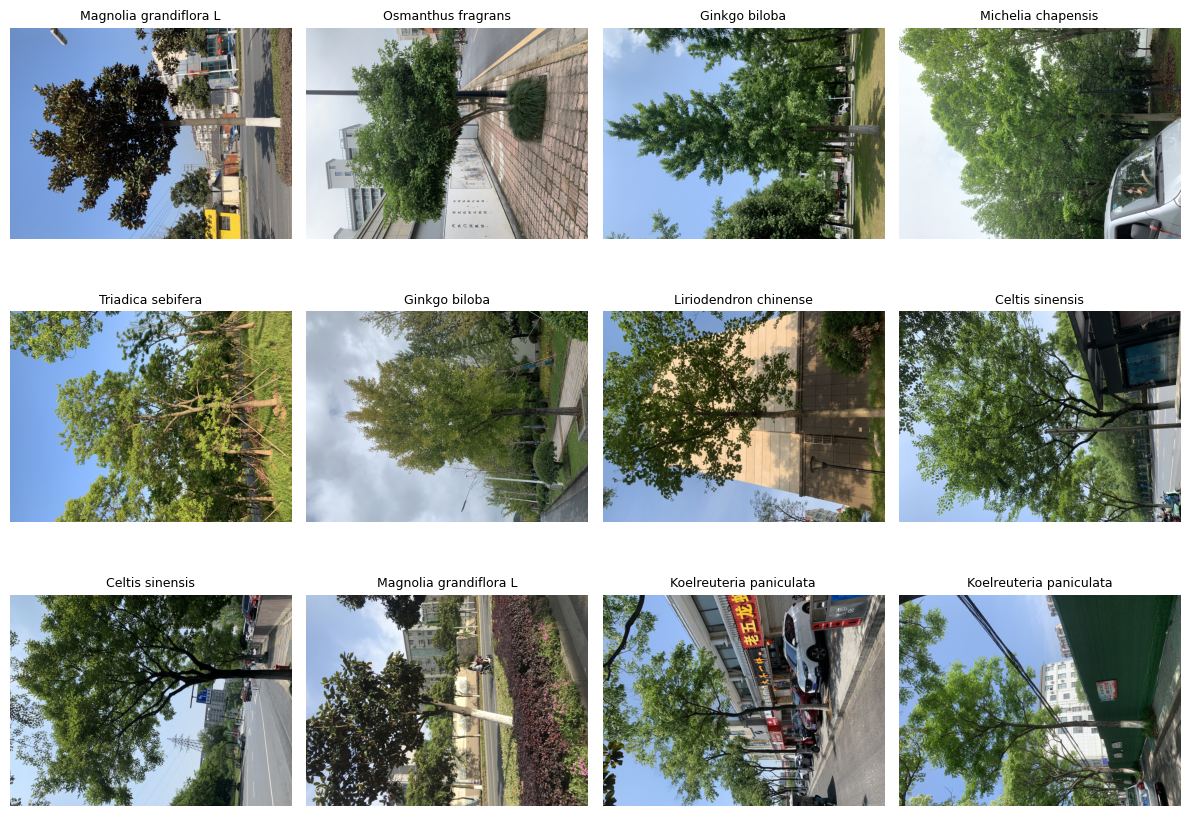

In [75]:
import random

random_indices = random.sample(range(len(train_data)), 12)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, index in zip(axes.flat, random_indices):
    image, label = train_data[index]
    
    ax.imshow(image)
    ax.set_title(train_data.classes[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.6 Check Image Orientation Metadata

During the image inspection, several images appeared to be rotated.

Before applying any rotation manually, we check whether the images contain EXIF orientation information.

EXIF metadata can contain information about how an image should be displayed. If this information is present, it can be corrected when the image is loaded.

This helps us avoid unnecessarily modifying images that are already stored correctly.

In [76]:
%pip install Pillow

from PIL import Image

image, label = train_data[0]

print("Image:", train_data.classes[label])
print("Image size:", image.size)

exif = image.getexif()

if 274 in exif:
    print("EXIF orientation:", exif[274])
else:
    print("No EXIF orientation information found.")

Note: you may need to restart the kernel to use updated packages.
Image: Acer palmatum
Image size: (1200, 1600)
No EXIF orientation information found.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 10.7 Check Class Distribution

The dataset contains 23 different tree species.

Before training the models, we check how many images are available for each species.

This helps us identify whether the dataset is reasonably balanced or whether some tree species have significantly more images than others.

Class imbalance can affect model performance because a model may have more opportunities to learn classes with a larger number of training images.

In [77]:
from collections import Counter

class_counts = Counter(train_data.targets)

print("Training images per class:\n")

for class_index, count in class_counts.items():
    print(train_data.classes[class_index], ":", count)

Training images per class:

Acer palmatum : 162
Cedrus deodara : 125
Celtis sinensis : 188
Cinnamomum camphora (Linn) Presl : 234
Elaeocarpus decipiens : 172
Flowering cherry : 106
Ginkgo biloba : 228
Koelreuteria paniculata : 223
Lagerstroemia indica : 65
Liquidambar formosana : 168
Liriodendron chinense : 182
Magnolia grandiflora L : 212
Magnolia liliflora Desr : 190
Michelia chapensis : 154
Osmanthus fragrans : 173
Photinia serratifolia : 120
Platanus : 193
Prunus cerasifera f. atropurpurea : 99
Salix babylonica : 136
Sapindus saponaria : 224
Styphnolobium japonicum : 157
Triadica sebifera : 154
Zelkova serrata : 185


## 10.8 Visualize the Class Distribution

A bar chart makes it easier to see whether some tree species have substantially more training images than others.

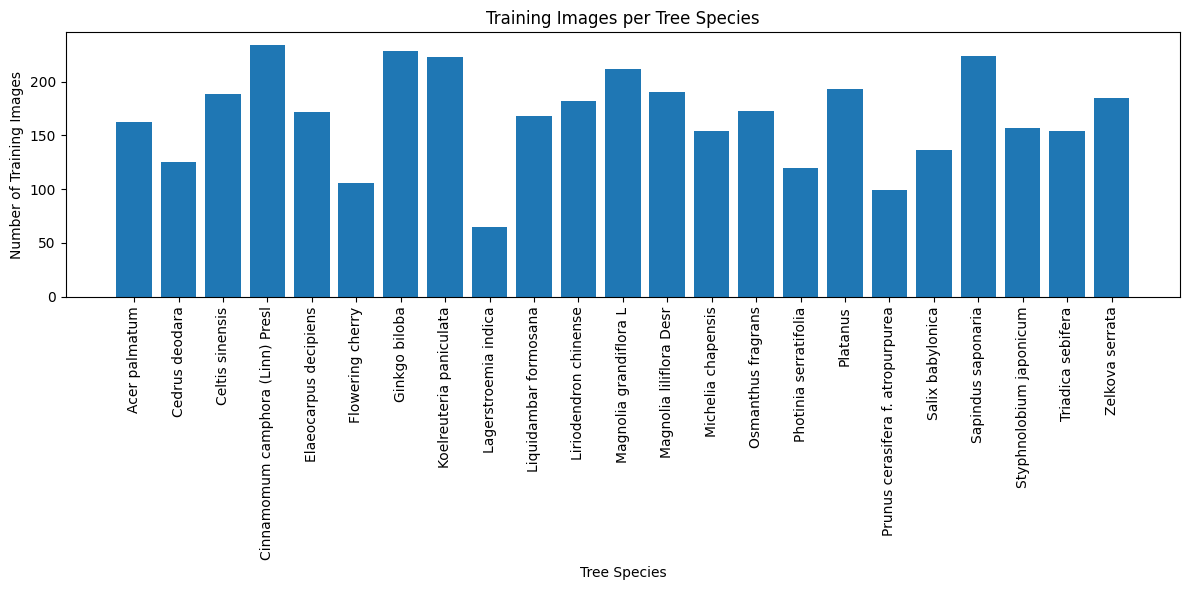

In [78]:
plt.figure(figsize=(12, 6))

plt.bar(
    train_data.classes,
    [class_counts[i] for i in range(len(train_data.classes))]
)

plt.xlabel("Tree Species")
plt.ylabel("Number of Training Images")
plt.title("Training Images per Tree Species")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# 11. Image Preprocessing

The dataset contains images with different resolutions and orientations. Before training the neural networks, the images need to be converted into a consistent format.

Because we are using pretrained ResNet models, the images will be processed using a format suitable for ImageNet-pretrained networks.

For the training data, we use data augmentation to introduce some variation into the images. This can help the model generalize better to images that it has not seen during training.

The validation and test images are only resized and normalized. Random augmentation is not applied to these datasets because they should provide a consistent evaluation of the models.

The preprocessing steps are:

- Resize and crop images to 224 × 224 pixels.
- Apply small random rotations during training.
- Apply random horizontal flipping during training.
- Convert images to PyTorch tensors.
- Normalize the images using the standard ImageNet mean and standard deviation.

## 11.1 Training Transformations

The training images use data augmentation because the dataset contains trees photographed from different viewpoints and under different conditions.

A small random rotation is used because the dataset contains images with different orientations. A horizontal flip is also used to create additional variation.

We use moderate transformations rather than strong transformations because excessive changes could make the tree species harder to recognize.

In [79]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10, fill=(128, 128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training transformations created successfully!")

Training transformations created successfully!


## 11.2 Validation and Test Transformations

The validation and test datasets should not use random augmentation.

We want the models to be evaluated using a consistent preprocessing procedure.

Therefore, validation and test images are resized, converted to tensors, and normalized using the same ImageNet normalization values.

In [80]:
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Validation and test transformations created successfully!")

Validation and test transformations created successfully!


## 11.3 Create Transformed Datasets

We now apply the training transformations to the training dataset and the evaluation transformations to the validation and test datasets.

The original datasets used above were useful for inspecting the images. These new datasets will be used for training and evaluation.

In [81]:
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)

print("Transformed datasets created successfully!")

Transformed datasets created successfully!


## 11.4 Check a Preprocessed Image

We display one transformed image to verify that the preprocessing pipeline works correctly.

Because the image has been normalized, its pixel values are no longer directly suitable for normal display. Therefore, we reverse the normalization before displaying it.

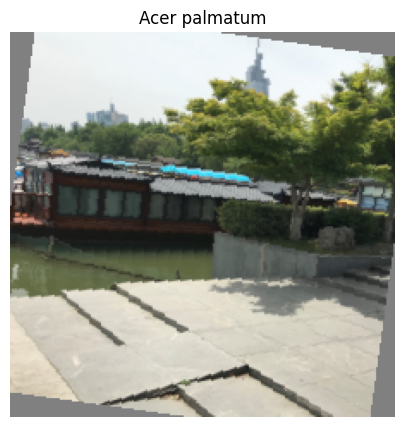

Processed image shape: torch.Size([3, 224, 224])


In [82]:
image, label = train_dataset[0]

# Reverse ImageNet normalization for display
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_display = image.numpy().transpose(1, 2, 0)
image_display = image_display * std + mean
image_display = np.clip(image_display, 0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(image_display)
plt.title(train_dataset.classes[label])
plt.axis("off")
plt.show()

print("Processed image shape:", image.shape)

# 12. Create DataLoaders

The datasets contain thousands of images, so we do not send all images to the neural network at the same time.

PyTorch DataLoader divides the dataset into smaller batches.

We use a batch size of 32. During training, the training images are shuffled so that the model does not always see the images in the same order.

The validation and test datasets are not shuffled because their purpose is evaluation, where a consistent order is sufficient.

In [83]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


## 12.1 Check One Training Batch

Before starting model training, we check one batch from the training DataLoader.

The expected image tensor shape is:

`[batch size, channels, height, width]`

For our project this should be approximately:

`[32, 3, 224, 224]`

In [84]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First few labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First few labels: tensor([19, 14, 15, 17, 12, 22, 16,  5, 18,  5])


## 12.2 Display a Training Batch

We display several images from one training batch to confirm that the DataLoader is providing correctly transformed images and their corresponding tree species labels.

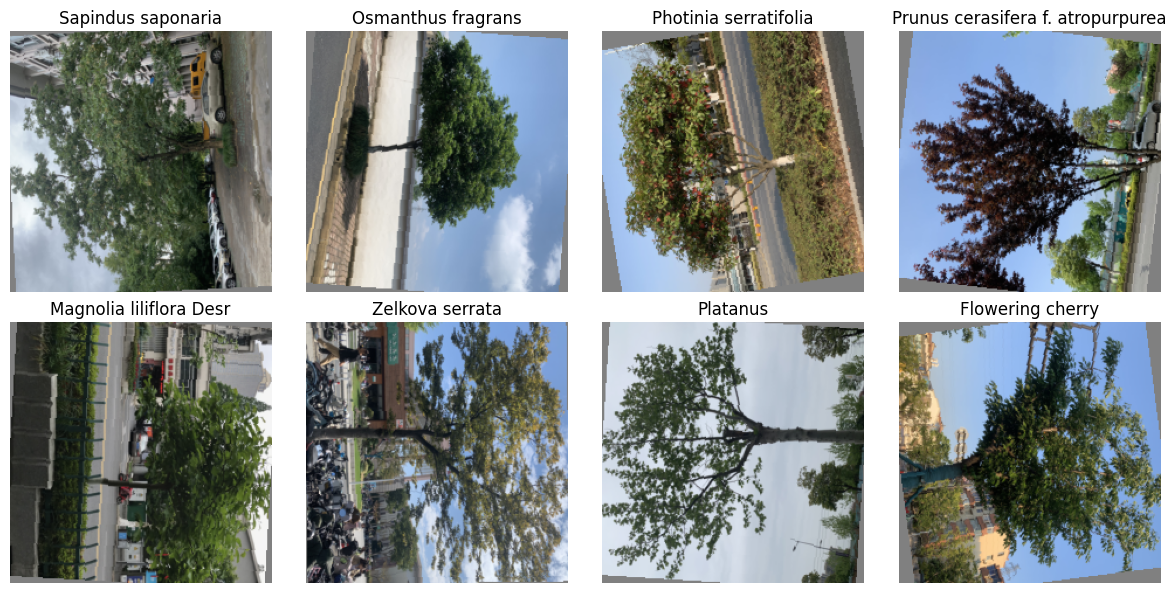

In [85]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i, ax in enumerate(axes.flat):

    image = images[i].numpy().transpose(1, 2, 0)

    # Reverse normalization for display
    image = image * std + mean
    image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.set_title(train_dataset.classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [86]:
from pathlib import Path

# Folder containing the trained checkpoints from the final project.
checkpoint_dir = Path(".")
checkpoint18 = checkpoint_dir / "resnet18_best.pth"
checkpoint50 = checkpoint_dir / "resnet50_best.pth"

for checkpoint in (checkpoint18, checkpoint50):
    if not checkpoint.is_file():
        raise FileNotFoundError(
            f"Missing trained checkpoint: {checkpoint.resolve()}. "
            "Obtain this file from the final project's training run "
            "and set checkpoint_dir to its folder."
        )

if not (
    train_dataset.class_to_idx
    == val_dataset.class_to_idx
    == test_dataset.class_to_idx
):
    raise ValueError("Training, validation, and test class mappings must match.")

num_classes = len(train_dataset.classes)
class_names = test_dataset.classes
# Use the same dataset and class ordering used to train these checkpoints.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model18 = models.resnet18(weights=None)
model18.fc = nn.Linear(model18.fc.in_features, num_classes)
model18.load_state_dict(
    torch.load(checkpoint18, map_location="cpu", weights_only=True)
)
model18 = model18.to(device)
model18.eval()

model50 = models.resnet50(weights=None)
model50.fc = nn.Linear(model50.fc.in_features, num_classes)
model50.load_state_dict(
    torch.load(checkpoint50, map_location="cpu", weights_only=True)
)
model50 = model50.to(device)
model50.eval()

print("Both trained checkpoints loaded successfully.")
print("Using device:", device)


Both trained checkpoints loaded successfully.
Using device: cpu


In [87]:
def get_predictions(model, data_loader):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)

            predictions = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    return (
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_probabilities)
    )

In [88]:
# Get ResNet18 predictions
y_true18, y_pred18, y_prob18 = get_predictions(
    model18,
    test_loader
)

# Get ResNet50 predictions
y_true50, y_pred50, y_prob50 = get_predictions(
    model50,
    test_loader
)

print("ResNet18 predictions collected:", len(y_pred18))
print("ResNet50 predictions collected:", len(y_pred50))

ResNet18 predictions collected: 472
ResNet50 predictions collected: 472


## 15.3 Calculate Accuracy, Precision, Recall and F1-score

The predictions from the test dataset are used to calculate the main classification metrics for both ResNet18 and ResNet50.

The following metrics are calculated:

- Accuracy
- Precision
- Recall
- F1-score

Macro averaging is used for precision, recall, and F1-score so that each tree species contributes equally to the overall result.

In [95]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ResNet18 metrics
accuracy18 = accuracy_score(y_true18, y_pred18)

precision18 = precision_score(
    y_true18,
    y_pred18,
    average="macro",
    zero_division=0
)

recall18 = recall_score(
    y_true18,
    y_pred18,
    average="macro",
    zero_division=0
)

f1_18 = f1_score(
    y_true18,
    y_pred18,
    average="macro",
    zero_division=0
)

# ResNet50 metrics
accuracy50 = accuracy_score(y_true50, y_pred50)

precision50 = precision_score(
    y_true50,
    y_pred50,
    average="macro",
    zero_division=0
)

recall50 = recall_score(
    y_true50,
    y_pred50,
    average="macro",
    zero_division=0
)

f1_50 = f1_score(
    y_true50,
    y_pred50,
    average="macro",
    zero_division=0
)

print("ResNet18 Test Results")
print("---------------------")
print(f"Accuracy : {accuracy18:.4f}")
print(f"Precision: {precision18:.4f}")
print(f"Recall   : {recall18:.4f}")
print(f"F1-score : {f1_18:.4f}")

print("\nResNet50 Test Results")
print("---------------------")
print(f"Accuracy : {accuracy50:.4f}")
print(f"Precision: {precision50:.4f}")
print(f"Recall   : {recall50:.4f}")
print(f"F1-score : {f1_50:.4f}")

ResNet18 Test Results
---------------------
Accuracy : 0.8136
Precision: 0.8711
Recall   : 0.8222
F1-score : 0.8254

ResNet50 Test Results
---------------------
Accuracy : 0.8771
Precision: 0.8976
Recall   : 0.8807
F1-score : 0.8831


## 15.7 N-Best Classification Results

The n-best classification results evaluate whether the correct tree species appears within the top n predictions of each model.

For example, top-1 accuracy corresponds to normal classification accuracy. 
Top-3 accuracy measures how often the correct species is included among the three highest-probability predictions.

The purpose is to determine whether increasing n reveals a meaningful difference between ResNet18 and ResNet50.

In [90]:
def top_k_accuracy(y_true, probabilities, k):
    top_k_predictions = np.argsort(probabilities, axis=1)[:, -k:]
    
    correct = 0
    
    for i in range(len(y_true)):
        if y_true[i] in top_k_predictions[i]:
            correct += 1
    
    return correct / len(y_true)


# Calculate top-k accuracy
max_k = 10

top_k_results18 = []
top_k_results50 = []

for k in range(1, max_k + 1):
    acc18 = top_k_accuracy(y_true18, y_prob18, k)
    acc50 = top_k_accuracy(y_true50, y_prob50, k)
    
    top_k_results18.append(acc18)
    top_k_results50.append(acc50)


# Print results
print("N-Best Classification Results")
print("-" * 45)

for k in range(1, max_k + 1):
    print(
        f"Top-{k}: "
        f"ResNet18 = {top_k_results18[k-1]:.4f} | "
        f"ResNet50 = {top_k_results50[k-1]:.4f}"
    )

N-Best Classification Results
---------------------------------------------
Top-1: ResNet18 = 0.8136 | ResNet50 = 0.8771
Top-2: ResNet18 = 0.8729 | ResNet50 = 0.9449
Top-3: ResNet18 = 0.9131 | ResNet50 = 0.9640
Top-4: ResNet18 = 0.9364 | ResNet50 = 0.9767
Top-5: ResNet18 = 0.9492 | ResNet50 = 0.9788
Top-6: ResNet18 = 0.9597 | ResNet50 = 0.9852
Top-7: ResNet18 = 0.9640 | ResNet50 = 0.9915
Top-8: ResNet18 = 0.9682 | ResNet50 = 0.9936
Top-9: ResNet18 = 0.9703 | ResNet50 = 0.9958
Top-10: ResNet18 = 0.9703 | ResNet50 = 0.9958


## 15.8 Visualization of N-Best Results

The top-k accuracy results are visualized to make the difference between the two models easier to observe.

The graph shows how classification accuracy changes as more possible predictions are considered.

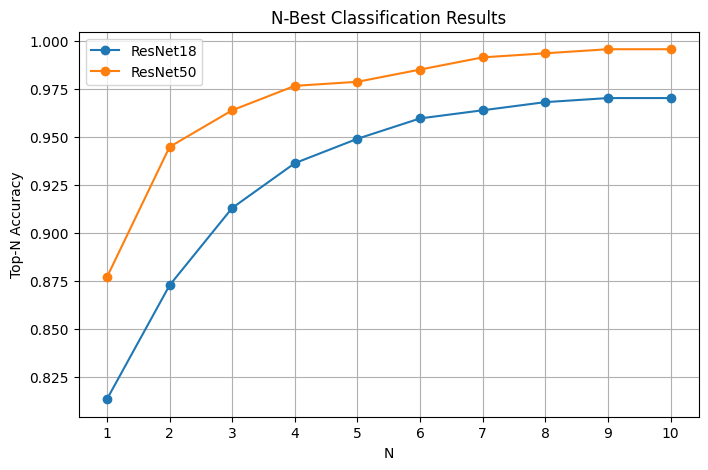

In [91]:
k_values = range(1, max_k + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    top_k_results18,
    marker="o",
    label="ResNet18"
)

plt.plot(
    k_values,
    top_k_results50,
    marker="o",
    label="ResNet50"
)

plt.xlabel("N")
plt.ylabel("Top-N Accuracy")
plt.title("N-Best Classification Results")
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)

plt.show()

### 15.9 Interpretation of N-Best Results

The models already have different performance at n = 1:
ResNet18 achieves 81.36%, while ResNet50 achieves 87.71%.

Among the tested values from n = 1 to n = 10, the largest
difference occurs at n = 2:

- ResNet18: 87.29%
- ResNet50: 94.49%
- Difference: approximately 7.20 percentage points

The difference generally becomes smaller as n increases.

Therefore, the models are already separated at n = 1.
There is no later value where separation first appears,
but n = 2 provides the largest observed separation within
the tested range.

## 15.10 Comparison of ResNet18 and ResNet50

The final test results of ResNet18 and ResNet50 are compared using accuracy, precision, recall, and F1-score.

The comparison is based on predictions from the same test dataset.

The results are also considered together with the confusion matrices and n-best classification results.

This provides a more complete evaluation than accuracy alone.

In [96]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "ResNet18": [
        accuracy18,
        precision18,
        recall18,
        f1_18
    ],
    "ResNet50": [
        accuracy50,
        precision50,
        recall50,
        f1_50
    ]
})

print(comparison)

      Metric  ResNet18  ResNet50
0   Accuracy  0.813559  0.877119
1  Precision  0.871070  0.897563
2     Recall  0.822230  0.880688
3   F1-score  0.825380  0.883119


## 15.11 Analysis of Misclassified Images

After evaluating the models, we inspect incorrectly classified test images.

The purpose is to identify repeated visual characteristics among the errors.

Possible factors include:

- Similar appearance between tree species
- Background objects
- Lighting conditions
- Different camera viewpoints
- Tree position in the image
- Occlusion
- Image quality
- The tree occupying only a small part of the image

The observations from this analysis will be used to decide whether an improvement to the preprocessing or data augmentation strategy is appropriate.

In [93]:
# Find misclassified ResNet50 images

misclassified_indices50 = np.where(
    y_true50 != y_pred50
)[0]

print("Number of misclassified ResNet50 images:",
      len(misclassified_indices50))

Number of misclassified ResNet50 images: 58


## 15.12 Inspect ResNet50 Misclassifications

A sample of incorrectly classified images is displayed below.

The true class and predicted class are shown for each image.

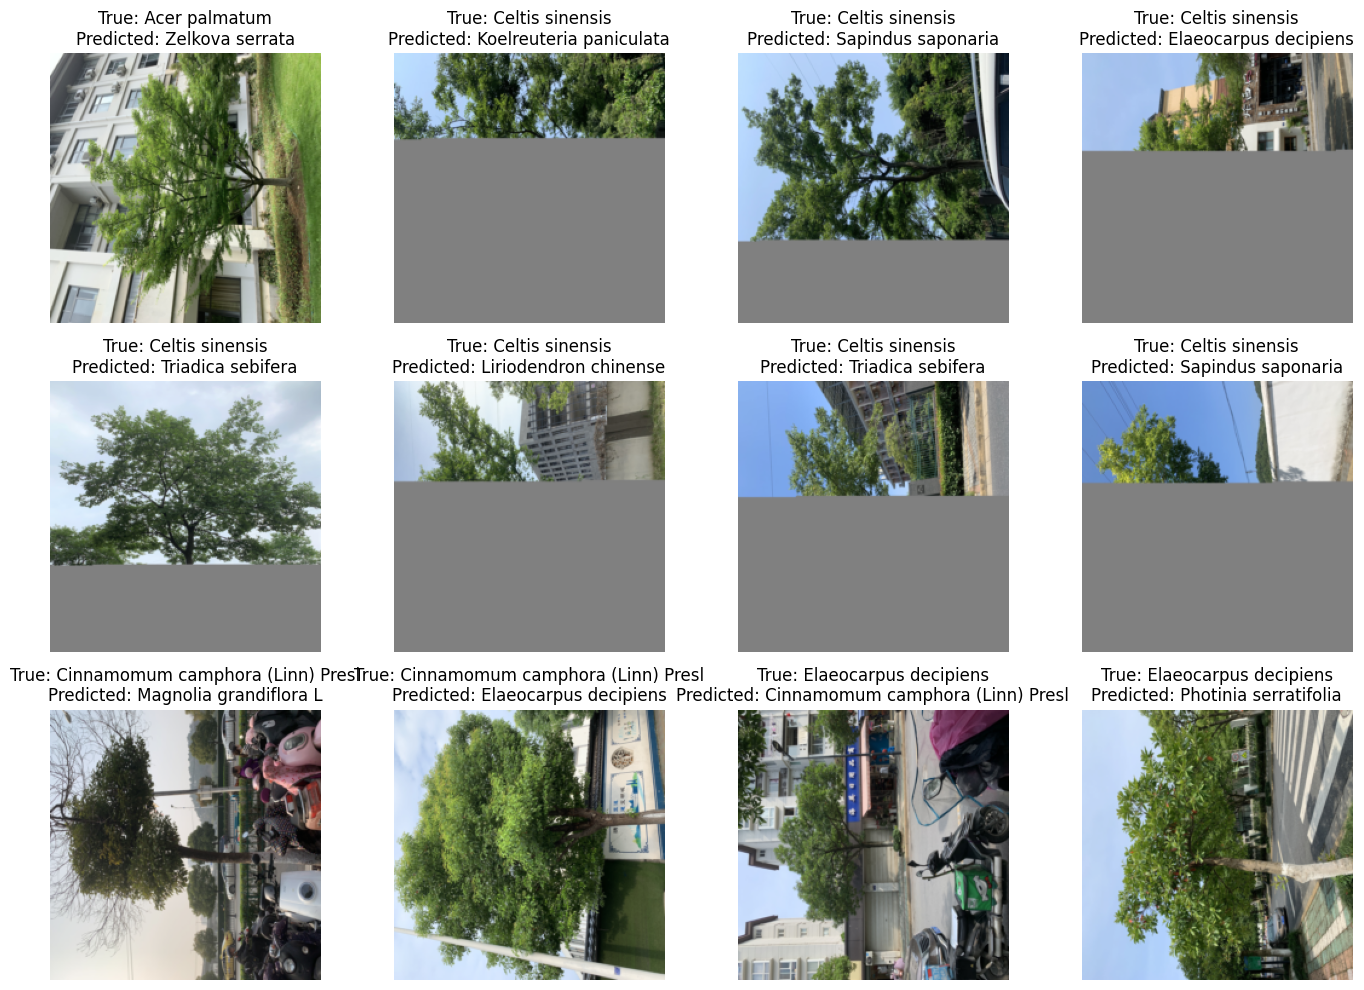

In [94]:
# Display several misclassified images

class_names = test_dataset.classes

num_images = min(12, len(misclassified_indices50))

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for i in range(num_images):
    
    idx = misclassified_indices50[i]
    
    image, true_label = test_dataset[idx]
    
    # Convert tensor image for displaying
    image_display = image.permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    
    # Normalize values for display
    image_display = np.clip(
        (image_display * std) + mean, 0, 1)
    
    predicted_label = y_pred50[idx]
    
    axes[i].imshow(image_display)
    
    axes[i].set_title(
        f"True: {class_names[true_label]}\n"
        f"Predicted: {class_names[predicted_label]}"
    )
    
    axes[i].axis("off")

for i in range(num_images, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()